<a href="https://colab.research.google.com/github/satyenncodes/mine-safety-ai-ml/blob/main/texmi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

import os
import gc
import numpy as np
import pandas as pd

CSV_PATH = "/content/methane_data.csv"
CHUNK_SIZE = 100_000

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        "CSV not found. Upload methane_data.csv to Colab and set CSV_PATH correctly."
    )

time_cols = ["year", "month", "day", "hour", "minute", "second"]

sensor_cols = [
    "AN311", "AN422", "AN423", "TP1721", "RH1722", "BA1723",
    "TP1711", "RH1712", "BA1713", "MM252", "MM261", "MM262",
    "MM263", "MM264", "MM256", "MM211", "CM861", "CR863",
    "P_864", "TC862", "WM868", "AMP1_IR", "AMP2_IR", "DMP3_IR",
    "DMP4_IR", "AMP5_IR", "F_SIDE", "V"
]

methane_cols = [
    "MM252", "MM261", "MM262", "MM263",
    "MM264", "MM256", "MM211", "CM861"
]

print("=" * 60)
print("1. FILE VERIFICATION")
print("=" * 60)
print("File:", CSV_PATH)
print("Size (GB):", round(os.path.getsize(CSV_PATH) / 1e9, 3))

header = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
print("Total columns:", len(header))
print("Columns:", header)

required = time_cols + sensor_cols
missing_columns = [c for c in required if c not in header]

if missing_columns:
    raise ValueError("Required columns missing: " + str(missing_columns))

print("\nAll expected timestamp and sensor columns are present.")

print("\n" + "=" * 60)
print("2. CHUNKED DATA QUALITY SCAN")
print("=" * 60)

total_rows = 0
missing_counts = pd.Series(0, index=required, dtype="int64")
valid_timestamp_rows = 0
invalid_timestamp_rows = 0
first_timestamp = None
last_timestamp = None
previous_timestamp = None
interval_counts = {}
sensor_stats = {}
threshold_counts = {c: {"ge_0_6": 0, "ge_1_0": 0, "ge_1_5": 0}
                    for c in methane_cols}
negative_counts = {c: 0 for c in methane_cols}
above_5_counts = {c: 0 for c in methane_cols}
invalid_timestamp_examples = []

for chunk in pd.read_csv(
    CSV_PATH, usecols=required, chunksize=CHUNK_SIZE, low_memory=False
):
    n = len(chunk)
    total_rows += n
    missing_counts += chunk[required].isna().sum()

    for c in sensor_cols:
        chunk[c] = pd.to_numeric(chunk[c], errors="coerce")

    ts = pd.to_datetime(
        chunk[time_cols].rename(columns={
            "year": "year", "month": "month", "day": "day",
            "hour": "hour", "minute": "minute", "second": "second"
        }),
        errors="coerce"
    )

    valid = ts.notna()
    valid_timestamp_rows += int(valid.sum())
    invalid_timestamp_rows += int((~valid).sum())

    if (~valid).any() and len(invalid_timestamp_examples) < 5:
        invalid_timestamp_examples.extend(
            chunk.loc[~valid, time_cols].head(
                5 - len(invalid_timestamp_examples)
            ).to_dict("records")
        )

    valid_ts = ts[valid]
    if len(valid_ts):
        if first_timestamp is None:
            first_timestamp = valid_ts.iloc[0]

        if previous_timestamp is not None:
            delta = (valid_ts.iloc[0] - previous_timestamp).total_seconds()
            interval_counts[delta] = interval_counts.get(delta, 0) + 1

        deltas = valid_ts.diff().dt.total_seconds().dropna()
        counts = deltas.value_counts()
        for delta, count in counts.items():
            interval_counts[float(delta)] = (
                interval_counts.get(float(delta), 0) + int(count)
            )

        last_timestamp = valid_ts.iloc[-1]
        previous_timestamp = last_timestamp

    for c in sensor_cols:
        values = chunk[c].dropna()
        if len(values):
            s = sensor_stats.setdefault(c, {
                "count": 0, "sum": 0.0, "sum_sq": 0.0,
                "min": np.inf, "max": -np.inf
            })
            s["count"] += len(values)
            s["sum"] += values.sum()
            s["sum_sq"] += np.square(values).sum()
            s["min"] = min(s["min"], values.min())
            s["max"] = max(s["max"], values.max())

    for c in methane_cols:
        values = chunk[c].dropna()
        threshold_counts[c]["ge_0_6"] += int((values >= 0.6).sum())
        threshold_counts[c]["ge_1_0"] += int((values >= 1.0).sum())
        threshold_counts[c]["ge_1_5"] += int((values >= 1.5).sum())
        negative_counts[c] += int((values < 0).sum())
        above_5_counts[c] += int((values > 5).sum())

    del chunk, ts
    gc.collect()

print("Total rows:", f"{total_rows:,}")
print("Valid timestamps:", f"{valid_timestamp_rows:,}")
print("Invalid timestamps:", f"{invalid_timestamp_rows:,}")
print("First timestamp:", first_timestamp)
print("Last timestamp:", last_timestamp)

print("\nMissing values by column:")
print(missing_counts[missing_counts > 0].sort_values(ascending=False)
      if (missing_counts > 0).any() else "No missing values.")

print("\nTimestamp interval summary:")
if interval_counts:
    intervals = pd.Series(interval_counts).sort_values(ascending=False)
    print("Most common intervals (seconds):")
    print(intervals.head(10))
    print("Intervals other than 1 second:",
          sum(v for k, v in interval_counts.items() if k != 1.0))
    print("Duplicate or out-of-order intervals:",
          sum(v for k, v in interval_counts.items() if k <= 0))
else:
    print("No timestamp intervals available.")

if invalid_timestamp_examples:
    print("Examples of invalid timestamp rows:", invalid_timestamp_examples)

print("\n" + "=" * 60)
print("3. SENSOR STATISTICS")
print("=" * 60)

rows = []
for c, s in sensor_stats.items():
    mean = s["sum"] / s["count"]
    variance = max(0.0, s["sum_sq"] / s["count"] - mean ** 2)
    rows.append({
        "sensor": c,
        "valid_count": s["count"],
        "mean": round(mean, 4),
        "std": round(np.sqrt(variance), 4),
        "min": s["min"],
        "max": s["max"]
    })

print(pd.DataFrame(rows).to_string(index=False))

print("\n" + "=" * 60)
print("4. METHANE THRESHOLD CHECK")
print("=" * 60)

threshold_rows = []
for c in methane_cols:
    threshold_rows.append({
        "sensor": c,
        "readings >= 0.6%": threshold_counts[c]["ge_0_6"],
        "readings >= 1.0%": threshold_counts[c]["ge_1_0"],
        "readings >= 1.5%": threshold_counts[c]["ge_1_5"],
        "negative readings": negative_counts[c],
        "readings > 5%": above_5_counts[c]
    })

print(pd.DataFrame(threshold_rows).to_string(index=False))

print("\n" + "=" * 60)
print("5. PRELIMINARY MODEL READINESS")
print("=" * 60)

target = "MM263"
if target in sensor_stats:
    print("Proposed target sensor:", target)
    print("Warning threshold: 1.0% CH4")
    print("Alarm threshold: 1.5% CH4")
    print("Readings at/above warning:", threshold_counts[target]["ge_1_0"])
    print("Readings at/above alarm:", threshold_counts[target]["ge_1_5"])
    print("Negative readings:", negative_counts[target])
    print("Readings above 5%:", above_5_counts[target])

    if threshold_counts[target]["ge_1_0"] == 0:
        print("WARNING: No readings reach the proposed warning threshold.")
    elif threshold_counts[target]["ge_1_0"] < 100:
        print("WARNING: Very few warning-level readings; model evaluation may be unreliable.")
    else:
        print("There are warning-level observations to investigate.")

print("\nVerification complete. Original CSV was not modified.")


1. FILE VERIFICATION
File: /content/methane_data.csv
Size (GB): 0.752
Total columns: 24
Columns: ['Unnamed: 0', '1106', '28.9', '67', '1105.4', '0', '0.3', '0.1', '0.5', '0.2', '0.5.1', '0.7', '52.4', '116', '94.1', '33', '3.22', '0.4', '0.6', '0.8', '0.9', '0.10', '0.11', '0.12']


ValueError: Required columns missing: ['year', 'month', 'day', 'hour', 'minute', 'second', 'AN311', 'AN422', 'AN423', 'TP1721', 'RH1722', 'BA1723', 'TP1711', 'RH1712', 'BA1713', 'MM252', 'MM261', 'MM262', 'MM263', 'MM264', 'MM256', 'MM211', 'CM861', 'CR863', 'P_864', 'TC862', 'WM868', 'AMP1_IR', 'AMP2_IR', 'DMP3_IR', 'DMP4_IR', 'AMP5_IR', 'F_SIDE', 'V']

In [5]:

with open("/content/methane_data.csv", "r", errors="replace") as f:
    for i in range(5):
        print(f"Line {i + 1}:", f.readline()[:500])


Line 1: ,1106,28.9,67,1105.4,0,0,0.1,0.5,0.2,0.5,0.7,52.4,116,94.1,33,3.22,0,0,0,0,0,0,0

Line 2: 2014,4,5,16,32,41,3.8,1.6,1.4,24.5,44,1106,28.9,67,1105.4,0,0,0.1,0.5,0.2,0.5,0.7,52.5,117,94.1,33,3.24,0,0,0,0,0,0,0

Line 3: 2014,4,5,16,32,42,3.8,1.6,1.4,24.5,44,1106,28.9,67,1105.4,0,0.1,0.1,0.5,0.2,0.5,0.7,52.5,117,94.1,33,3.24,0,0,0,0,0,0,0

Line 4: 2014,4,5,16,32,43,3.8,1.6,1.4,24.5,44,1106,28.9,67,1105.4,0,0.1,0.1,0.5,0.2,0.5,0.7,52.5,117,94.1,33,3.24,0,0,0,0,0,0,0

Line 5: 2014,4,5,16,32,44,3.8,1.6,1.4,24.5,44,1106,28.9,67,1105.4,0,0.1,0.1,0.5,0.2,0.5,0.7,52.5,117,94.1,33,3.24,0,0,0,0,0,0,0



In [6]:

import os
import gc
import numpy as np
import pandas as pd

CSV_PATH = "/content/methane_data.csv"
CHUNK_SIZE = 100_000

COLUMNS = [
    "year", "month", "day", "hour", "minute", "second",
    "AN311", "AN422", "AN423", "TP1721", "RH1722",
    "BA1723", "TP1711", "RH1712", "BA1713",
    "MM252", "MM261", "MM262", "MM263", "MM264",
    "MM256", "MM211", "CM861", "CR863", "P_864",
    "TC862", "WM868", "AMP1_IR", "AMP2_IR",
    "DMP3_IR", "DMP4_IR", "AMP5_IR", "F_SIDE", "V"
]

TIME_COLS = ["year", "month", "day", "hour", "minute", "second"]
SENSORS = [c for c in COLUMNS if c not in TIME_COLS]
METHANE = [
    "MM252", "MM261", "MM262", "MM263",
    "MM264", "MM256", "MM211", "CM861"
]

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"{CSV_PATH} not found. Upload the full methane_data.csv first."
    )

print("=" * 65)
print("1. FILE AND FORMAT")
print("=" * 65)
print("File size (GB):", round(os.path.getsize(CSV_PATH) / 1e9, 3))
print("Expected columns:", len(COLUMNS))

# The first line is an incomplete extra record; skip it.
# All subsequent rows must contain the 34 expected fields.
reader = pd.read_csv(
    CSV_PATH,
    header=None,
    skiprows=1,
    names=COLUMNS,
    chunksize=CHUNK_SIZE,
    low_memory=False,
    on_bad_lines="error"
)

total_rows = 0
missing = pd.Series(0, index=COLUMNS, dtype="int64")
stats = {
    c: {"n": 0, "sum": 0.0, "sum_sq": 0.0,
        "min": np.inf, "max": -np.inf}
    for c in SENSORS
}
thresholds = {
    c: {"ge_0_6": 0, "ge_1_0": 0, "ge_1_5": 0}
    for c in METHANE
}
negative = {c: 0 for c in METHANE}
above_5 = {c: 0 for c in METHANE}

first_ts = None
last_ts = None
previous_ts = None
interval_counts = {}
invalid_ts = 0
timestamp_rows = 0
bad_rows = 0
first_rows = []
last_rows = []
target_samples = []

print("\nScanning the full file in chunks...")

for chunk in reader:
    total_rows += len(chunk)
    missing += chunk.isna().sum()

    if len(first_rows) < 3:
        first_rows.append(chunk.head(3 - len(first_rows)).copy())
    last_rows.append(chunk.tail(3).copy())
    last_rows = [pd.concat(last_rows, ignore_index=True).tail(3)]

    for c in SENSORS:
        chunk[c] = pd.to_numeric(chunk[c], errors="coerce")

    ts = pd.to_datetime(
        chunk[TIME_COLS], errors="coerce"
    )
    valid_ts = ts.notna()
    timestamp_rows += int(valid_ts.sum())
    invalid_ts += int((~valid_ts).sum())

    valid_values = ts[valid_ts]
    if len(valid_values):
        if first_ts is None:
            first_ts = valid_values.iloc[0]

        deltas = valid_values.diff().dt.total_seconds().dropna()
        if previous_ts is not None:
            delta = (valid_values.iloc[0] - previous_ts).total_seconds()
            interval_counts[delta] = interval_counts.get(delta, 0) + 1

        for delta, count in deltas.value_counts().items():
            interval_counts[float(delta)] = (
                interval_counts.get(float(delta), 0) + int(count)
            )

        previous_ts = valid_values.iloc[-1]
        last_ts = previous_ts

    for c in SENSORS:
        values = chunk[c].dropna()
        if len(values):
            s = stats[c]
            s["n"] += len(values)
            s["sum"] += float(values.sum())
            s["sum_sq"] += float(np.square(values).sum())
            s["min"] = min(s["min"], float(values.min()))
            s["max"] = max(s["max"], float(values.max()))

    for c in METHANE:
        values = chunk[c].dropna()
        thresholds[c]["ge_0_6"] += int((values >= 0.6).sum())
        thresholds[c]["ge_1_0"] += int((values >= 1.0).sum())
        thresholds[c]["ge_1_5"] += int((values >= 1.5).sum())
        negative[c] += int((values < 0).sum())
        above_5[c] += int((values > 5).sum())

    # Retain only a small sample to assess whether the target is constant.
    if len(target_samples) < 100_000:
        target_samples.extend(
            chunk["MM263"].dropna().head(
                100_000 - len(target_samples)
            ).tolist()
        )

    del chunk, ts, valid_values
    gc.collect()

print("\n" + "=" * 65)
print("2. ROW AND TIMESTAMP VERIFICATION")
print("=" * 65)
print("Total valid-format data rows:", f"{total_rows:,}")
print("Valid timestamps:", f"{timestamp_rows:,}")
print("Invalid timestamps:", f"{invalid_ts:,}")
print("First timestamp:", first_ts)
print("Last timestamp:", last_ts)

print("\nMost common timestamp intervals (seconds):")
print(pd.Series(interval_counts).sort_values(ascending=False).head(10))
print("Intervals other than 1 second:",
      sum(v for k, v in interval_counts.items() if k != 1.0))
print("Duplicate/out-of-order intervals:",
      sum(v for k, v in interval_counts.items() if k <= 0))

print("\n" + "=" * 65)
print("3. MISSING VALUES")
print("=" * 65)
print(missing[missing > 0].sort_values(ascending=False)
      if (missing > 0).any() else "No missing values.")

print("\n" + "=" * 65)
print("4. SENSOR STATISTICS")
print("=" * 65)

rows = []
for c, s in stats.items():
    if s["n"] == 0:
        continue
    mean = s["sum"] / s["n"]
    variance = max(0.0, s["sum_sq"] / s["n"] - mean**2)
    rows.append({
        "sensor": c,
        "count": s["n"],
        "mean": round(mean, 4),
        "std": round(np.sqrt(variance), 4),
        "min": s["min"],
        "max": s["max"]
    })

print(pd.DataFrame(rows).to_string(index=False))

print("\n" + "=" * 65)
print("5. METHANE THRESHOLD CHECK")
print("=" * 65)

print(pd.DataFrame([
    {
        "sensor": c,
        ">=0.6%": thresholds[c]["ge_0_6"],
        ">=1.0%": thresholds[c]["ge_1_0"],
        ">=1.5%": thresholds[c]["ge_1_5"],
        "negative": negative[c],
        ">5%": above_5[c]
    }
    for c in METHANE
]).to_string(index=False))

print("\n" + "=" * 65)
print("6. TARGET AND MODEL READINESS")
print("=" * 65)

target_values = pd.Series(target_samples, dtype="float64")
print("MM263 sample unique values:", target_values.nunique())
print("MM263 sample value counts:")
print(target_values.value_counts().sort_index().head(30))

print("\nProposed target: MM263 reaching 1.0% CH4")
print("Warning-level readings:", thresholds["MM263"]["ge_1_0"])
print("Alarm-level readings:", thresholds["MM263"]["ge_1_5"])

if total_rows < 1_000_000:
    print("\nWARNING: This file has fewer than 1 million rows.")
    print("Confirm this is the complete dataset before training.")
elif thresholds["MM263"]["ge_1_0"] == 0:
    print("\nWARNING: No MM263 readings reach 1.0%.")
    print("A model cannot learn this positive event from this file.")
else:
    print("\nPositive warning-level readings exist.")
    print("A chronological prediction experiment may be possible.")

constant_sensors = [
    c for c, s in stats.items()
    if s["n"] > 0 and s["min"] == s["max"]
]
print("\nConstant sensors to exclude from model features:", constant_sensors)

print("\n" + "=" * 65)
print("VERIFICATION COMPLETE — ORIGINAL FILE NOT MODIFIED")
print("=" * 65)


1. FILE AND FORMAT
File size (GB): 0.752
Expected columns: 34

Scanning the full file in chunks...

2. ROW AND TIMESTAMP VERIFICATION
Total valid-format data rows: 6,206,369
Valid timestamps: 6,206,369
Invalid timestamps: 0
First timestamp: 2014-04-05 16:32:41
Last timestamp: 2014-06-16 12:32:09

Most common timestamp intervals (seconds):
1.0    6206368
dtype: int64
Intervals other than 1 second: 0
Duplicate/out-of-order intervals: 0

3. MISSING VALUES
No missing values.

4. SENSOR STATISTICS
 sensor   count      mean     std    min     max
  AN311 6206369    3.4282  0.7221 -266.0    5.00
  AN422 6206369    1.6472  0.1255    0.0    2.40
  AN423 6206369    1.5053  0.3240   -2.4    3.70
 TP1721 6206369   25.9373  0.7654    0.0   27.90
 RH1722 6206369   51.6402  5.8028    0.0   71.00
 BA1723 6206369 1105.2467  5.1322    0.0 1122.40
 TP1711 6206369   29.1284  0.7180    0.0   31.20
 RH1712 6206369   70.1161  7.0887    0.0   86.00
 BA1713 6206369 1104.7074  5.1342    0.0 1121.70
  MM252 6206

In [8]:

import os
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

CSV_PATH = "/content/methane_data.csv"
OUT_PATH = "/content/methane_hazard_model.joblib"
DATA_PATH = "/content/methane_training_data.csv"
CHUNK_SIZE = 100_000
SAMPLE_EVERY = 10
HORIZON = 60
THRESHOLD = 1.0

columns = [
    "year", "month", "day", "hour", "minute", "second",
    "AN311", "AN422", "AN423", "TP1721", "RH1722",
    "BA1723", "TP1711", "RH1712", "BA1713",
    "MM252", "MM261", "MM262", "MM263", "MM264",
    "MM256", "MM211", "CM861", "CR863", "P_864",
    "TC862", "WM868", "AMP1_IR", "AMP2_IR",
    "DMP3_IR", "DMP4_IR", "AMP5_IR", "F_SIDE", "V"
]

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"Dataset not found: {CSV_PATH}")

# Exclude CM861 because its observed range appears inconsistent
# with a methane percentage reading; investigate it separately.
features = [
    "AN311", "AN422", "AN423", "TP1721", "RH1722",
    "BA1723", "TP1711", "RH1712", "BA1713",
    "MM252", "MM261", "MM262", "MM263", "MM264",
    "MM256", "MM211", "CR863", "P_864", "TC862",
    "WM868", "AMP1_IR", "AMP2_IR", "DMP3_IR",
    "DMP4_IR", "AMP5_IR", "F_SIDE", "V"
]

print("Step 1/4: Preparing chunked training data...")

# Do not use the incomplete first line as a data record.
reader = pd.read_csv(
    CSV_PATH,
    header=None,
    skiprows=1,
    names=columns,
    chunksize=CHUNK_SIZE,
    low_memory=False
)

if os.path.exists(DATA_PATH):
    os.remove(DATA_PATH)

carry = None
row_offset = 0
written = 0
positive = 0
first_write = True

methane_cols = [
    "MM252", "MM261", "MM262", "MM263",
    "MM264", "MM256", "MM211"
]

for chunk in reader:
    current_len = len(chunk)
    chunk[features] = chunk[features].apply(pd.to_numeric, errors="coerce")

    # Replace implausible methane values with missing values.
    for c in methane_cols:
        chunk.loc[(chunk[c] < 0) | (chunk[c] > 5), c] = np.nan

    # Replace obvious invalid physical/sensor readings.
    for c in ["AN311", "AN422", "AN423"]:
        chunk.loc[(chunk[c] < 0) | (chunk[c] > 15), c] = np.nan

    for c in ["TP1721", "TP1711", "TC862"]:
        chunk.loc[(chunk[c] < 0) | (chunk[c] > 80), c] = np.nan

    for c in ["RH1722", "RH1712"]:
        chunk.loc[(chunk[c] < 0) | (chunk[c] > 100), c] = np.nan

    for c in ["BA1723", "BA1713"]:
        chunk.loc[(chunk[c] < 800) | (chunk[c] > 1200), c] = np.nan

    for c in ["AMP1_IR", "AMP2_IR", "DMP3_IR", "DMP4_IR", "AMP5_IR"]:
        chunk.loc[(chunk[c] < 0) | (chunk[c] > 300), c] = np.nan

    # Retain raw row positions so sampling stays aligned across chunks.
    chunk["_pos"] = np.arange(row_offset, row_offset + current_len)
    row_offset += current_len

    combined = (
        pd.concat([carry, chunk], ignore_index=True)
        if carry is not None else chunk
    )

    # Target uses the next 60 seconds, excluding the current second.
    future_max = (
        combined["MM263"].shift(-1).iloc[::-1]
        .rolling(HORIZON, min_periods=HORIZON)
        .max().iloc[::-1]
    )

    combined["_target"] = (future_max >= THRESHOLD).astype(float)
    combined.loc[future_max.isna(), "_target"] = np.nan

    # Do not emit the final 60 rows yet; the next chunk supplies their future.
    if len(combined) > HORIZON:
        eligible = combined.iloc[:-HORIZON]
        sampled = eligible[
            (eligible["_pos"] % SAMPLE_EVERY) == 0
        ].copy()

        sampled = sampled.dropna(subset=["_target"])
        sampled["target"] = sampled["_target"].astype("int8")
        output = sampled[features + ["target"]]

        output.to_csv(
            DATA_PATH,
            mode="w" if first_write else "a",
            header=first_write,
            index=False
        )
        first_write = False
        written += len(output)
        positive += int(output["target"].sum())

    carry = combined.tail(HORIZON).drop(columns=["_target"], errors="ignore").copy()

    del chunk, combined, future_max
    gc.collect()

# No further future rows exist after the end of the file.
del carry
gc.collect()

if written < 1000:
    raise ValueError("Too few usable training rows were generated.")

print("Sampled rows:", f"{written:,}")
print("Positive future-warning examples:", f"{positive:,}")
print("Training data saved:", DATA_PATH)

print("\nStep 2/4: Loading the reduced dataset...")
data = pd.read_csv(DATA_PATH)
data = data.replace([np.inf, -np.inf], np.nan)

# Remove features that have no valid values or are constant.
usable_features = [
    c for c in features
    if data[c].notna().any() and data[c].nunique(dropna=True) > 1
]

print("Features used:", len(usable_features))
print(usable_features)

# Keep chronological order: never shuffle the time series.
split = int(len(data) * 0.8)
train = data.iloc[:split]
test = data.iloc[split:]

X_train = train[usable_features]
y_train = train["target"].astype(int)
X_test = test[usable_features]
y_test = test["target"].astype(int)

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Training positives:", int(y_train.sum()))
print("Testing positives:", int(y_test.sum()))

if y_train.nunique() < 2:
    raise ValueError("Training set has only one class; cannot train classifier.")

print("\nStep 3/4: Training classifier...")

# Weight positive events so rare hazards influence training.
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
sample_weights = np.where(
    y_train.to_numpy() == 1,
    negative_count / max(positive_count, 1),
    1.0
)

model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=2.0,
    random_state=42
)

model.fit(X_train, y_train, sample_weight=sample_weights)

print("\nStep 4/4: Evaluating on later time period...")
probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print("\nClassification report at probability threshold 0.5:")
print(classification_report(y_test, predictions, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, predictions))

if y_test.nunique() == 2:
    print("Average precision:",
          round(average_precision_score(y_test, probabilities), 4))
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))
else:
    print("ROC-AUC and average precision are unavailable: test set has one class.")

joblib.dump({
    "model": model,
    "features": usable_features,
    "threshold_percent_ch4": THRESHOLD,
    "prediction_horizon_seconds": HORIZON,
    "sampling_interval_seconds": SAMPLE_EVERY,
    "target_sensor": "MM263"
}, OUT_PATH)

print("\nModel saved to:", OUT_PATH)
print("Training dataset saved to:", DATA_PATH)


Step 1/4: Preparing chunked training data...
Sampled rows: 586,784
Positive future-warning examples: 2,310
Training data saved: /content/methane_training_data.csv

Step 2/4: Loading the reduced dataset...
Features used: 27
['AN311', 'AN422', 'AN423', 'TP1721', 'RH1722', 'BA1723', 'TP1711', 'RH1712', 'BA1713', 'MM252', 'MM261', 'MM262', 'MM263', 'MM264', 'MM256', 'MM211', 'CR863', 'P_864', 'TC862', 'WM868', 'AMP1_IR', 'AMP2_IR', 'DMP3_IR', 'DMP4_IR', 'AMP5_IR', 'F_SIDE', 'V']
Training rows: 469427
Testing rows: 117357
Training positives: 2041
Testing positives: 269

Step 3/4: Training classifier...

Step 4/4: Evaluating on later time period...

Classification report at probability threshold 0.5:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    117088
           1       0.39      0.52      0.44       269

    accuracy                           1.00    117357
   macro avg       0.69      0.76      0.72    117357
weighted avg       1.00 

In [9]:

import os
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    fbeta_score
)

DATA_PATH = "/content/methane_training_data.csv"
MODEL_PATH = "/content/methane_hazard_model_improved.joblib"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Training dataset not found. Keep the existing "
        "methane_training_data.csv in /content."
    )

print("Loading previously prepared dataset...")
data = pd.read_csv(DATA_PATH)

if "target" not in data.columns:
    raise ValueError("The dataset does not contain the target column.")

data = data.replace([np.inf, -np.inf], np.nan)
data["target"] = pd.to_numeric(data["target"], errors="coerce")
data = data.dropna(subset=["target"]).reset_index(drop=True)
data["target"] = data["target"].astype(int)

features = [
    c for c in data.columns
    if c != "target" and data[c].notna().any()
    and data[c].nunique(dropna=True) > 1
]

if len(features) == 0:
    raise ValueError("No usable sensor features found.")

# Chronological split: 70% training, 10% validation, 20% final test.
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

train = data.iloc[:train_end]
val = data.iloc[train_end:val_end]
test = data.iloc[val_end:]

X_train = train[features]
y_train = train["target"].to_numpy()

X_val = val[features]
y_val = val["target"].to_numpy()

X_test = test[features]
y_test = test["target"].to_numpy()

print("\nRows:", n)
print("Training:", len(train), "| positives:", int(y_train.sum()))
print("Validation:", len(val), "| positives:", int(y_val.sum()))
print("Final test:", len(test), "| positives:", int(y_test.sum()))
print("Features:", features)

if len(np.unique(y_train)) < 2 or len(np.unique(y_val)) < 2:
    raise ValueError(
        "Training or validation period contains only one class. "
        "Threshold tuning cannot proceed reliably."
    )

# Fit imputation on training data only.
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

print("\nTraining candidate models...")

candidates = []
thresholds = np.arange(0.01, 0.96, 0.01)

for positive_weight in [20, 50, 100]:
    print(f"\nPositive-class weight: {positive_weight}")

    weights = np.where(
        y_train == 1,
        positive_weight,
        1.0
    )

    candidate = HistGradientBoostingClassifier(
        max_iter=120,
        learning_rate=0.06,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=2.0,
        random_state=42
    )

    candidate.fit(X_train, y_train, sample_weight=weights)
    val_prob = candidate.predict_proba(X_val)[:, 1]

    best = None

    # Prefer the highest precision among thresholds achieving
    # at least 80% validation recall; use F2 as a tie-breaker.
    for threshold in thresholds:
        pred = (val_prob >= threshold).astype(int)
        recall = recall_score(y_val, pred, zero_division=0)
        precision = precision_score(y_val, pred, zero_division=0)
        f2 = fbeta_score(y_val, pred, beta=2, zero_division=0)

        if recall >= 0.80:
            result = (precision, f2, recall, threshold)
            if best is None or result[:2] > best[:2]:
                best = result

    if best is None:
        # If no threshold reaches the recall goal, maximize validation F2.
        scores = [
            (
                fbeta_score(
                    y_val, (val_prob >= t).astype(int),
                    beta=2, zero_division=0
                ),
                t
            )
            for t in thresholds
        ]
        _, threshold = max(scores)
        best_pred = (val_prob >= threshold).astype(int)
        best = (
            precision_score(y_val, best_pred, zero_division=0),
            fbeta_score(y_val, best_pred, beta=2, zero_division=0),
            recall_score(y_val, best_pred, zero_division=0),
            threshold
        )

    precision, f2, recall, threshold = best

    print("Selected validation threshold:", round(threshold, 3))
    print("Validation precision:", round(precision, 4))
    print("Validation recall:", round(recall, 4))
    print("Validation F2:", round(f2, 4))

    candidates.append({
        "weight": positive_weight,
        "model": candidate,
        "threshold": threshold,
        "val_precision": precision,
        "val_recall": recall,
        "val_f2": f2
    })

    del val_prob
    gc.collect()

# Select the model by validation F2, not final test performance.
selected = max(candidates, key=lambda item: item["val_f2"])
model = selected["model"]
threshold = selected["threshold"]

print("\n" + "=" * 55)
print("SELECTED MODEL")
print("=" * 55)
print("Positive-class weight:", selected["weight"])
print("Decision threshold:", round(threshold, 4))
print("Validation precision:", round(selected["val_precision"], 4))
print("Validation recall:", round(selected["val_recall"], 4))
print("Validation F2:", round(selected["val_f2"], 4))

print("\nEvaluating once on the final chronological test set...")
test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

print("\nClassification report:")
print(classification_report(y_test, test_pred, zero_division=0))
print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_test, test_pred))

print("Test precision:", round(
    precision_score(y_test, test_pred, zero_division=0), 4
))
print("Test recall:", round(
    recall_score(y_test, test_pred, zero_division=0), 4
))
print("Test F2:", round(
    fbeta_score(y_test, test_pred, beta=2, zero_division=0), 4
))
print("Test alert count:", int(test_pred.sum()))
print("Actual warning cases:", int(y_test.sum()))

if len(np.unique(y_test)) == 2:
    print("Test average precision:", round(
        average_precision_score(y_test, test_prob), 4
    ))
    print("Test ROC-AUC:", round(
        roc_auc_score(y_test, test_prob), 4
    ))

joblib.dump({
    "model": model,
    "imputer": imputer,
    "features": features,
    "threshold": float(threshold),
    "target_sensor": "MM263",
    "warning_level_percent_ch4": 1.0,
    "prediction_horizon_seconds": 60,
    "sampling_interval_seconds": 10,
    "positive_class_weight": selected["weight"],
    "validation_recall": selected["val_recall"],
    "validation_precision": selected["val_precision"]
}, MODEL_PATH)

print("\nImproved model saved to:", MODEL_PATH)


Loading previously prepared dataset...

Rows: 586784
Training: 410748 | positives: 1941
Validation: 58679 | positives: 100
Final test: 117357 | positives: 269
Features: ['AN311', 'AN422', 'AN423', 'TP1721', 'RH1722', 'BA1723', 'TP1711', 'RH1712', 'BA1713', 'MM252', 'MM261', 'MM262', 'MM263', 'MM264', 'MM256', 'MM211', 'CR863', 'P_864', 'TC862', 'WM868', 'AMP1_IR', 'AMP2_IR', 'DMP3_IR', 'DMP4_IR', 'AMP5_IR', 'F_SIDE', 'V']

Training candidate models...

Positive-class weight: 20
Selected validation threshold: 0.19
Validation precision: 0.4624
Validation recall: 0.8
Validation F2: 0.6981

Positive-class weight: 50
Selected validation threshold: 0.08
Validation precision: 0.4309
Validation recall: 0.81
Validation F2: 0.6888

Positive-class weight: 100
Selected validation threshold: 0.11
Validation precision: 0.4145
Validation recall: 0.8
Validation F2: 0.6745

SELECTED MODEL
Positive-class weight: 20
Decision threshold: 0.19
Validation precision: 0.4624
Validation recall: 0.8
Validation F

Loading prepared dataset...
Total rows: 586784
Features: 27
Train positives: 1941
Validation positives: 100
Test positives: 269
Rows used for fitting: 250000

1. Sensor-threshold baseline
Threshold baseline: threshold=0.500, test recall=0.770, precision=0.035, F2=0.147, AP=0.027

2. Random Forest
Random Forest: threshold=0.170, test recall=0.613, precision=0.225, F2=0.456, AP=0.426

3. Histogram Gradient Boosting
Histogram Gradient Boosting: threshold=0.100, test recall=0.502, precision=0.228, F2=0.405, AP=0.450

4. XGBoost
XGBoost: threshold=0.030, test recall=0.558, precision=0.154, F2=0.365, AP=0.426

5. LSTM sequence model
Epoch 1/12
1605/1605 ━━━━━━━━━━━━━━━━━━━━ 96s 57ms/step - loss: 0.1351 - pr_auc: 0.4152 - recall: 0.6981 - val_loss: 0.0080 - val_pr_auc: 0.5384 - val_recall: 0.0000e+00
Epoch 2/12
1605/1605 ━━━━━━━━━━━━━━━━━━━━ 89s 56ms/step - loss: 0.0794 - pr_auc: 0.5888 - recall: 0.8228 - val_loss: 0.0062 - val_pr_auc: 0.5313 - val_recall: 0.2000
Epoch 3/12
1605/1605 ━━━━━━━━

,model,threshold,val_precision,val_recall,val_F2,test_precision,test_recall,test_F2,test_average_precision,test_ROC_AUC,TN,FP,FN,TP
0,Random Forest,0.17,0.4475,0.81,0.6971,0.2251,0.6134,0.4561,0.4259,0.9319,116515,568,104,165
1,LSTM,0.15,0.3597,0.91,0.6968,0.3973,0.5390,0.5031,0.3345,0.9682,116863,220,124,145
2,Histogram Gradient Boosting,0.10,0.3705,0.83,0.6651,0.2280,0.5019,0.4047,0.4496,0.8926,116626,457,134,135
3,XGBoost,0.03,0.4156,0.64,0.5776,0.1537,0.5576,0.3655,0.4259,0.9155,116257,826,119,150
4,Threshold baseline,0.50,0.1222,0.92,0.3990,0.0347,0.7695,0.1469,0.0272,0.8601,111318,5765,62,207



Selected using validation F2: Random Forest
Selected threshold: 0.17
The selected candidate is a trained model.

Selected candidate's test metrics:
test_precision: 0.22510231923601637
test_recall: 0.6133828996282528
test_F2: 0.4560530679933665
test_average_precision: 0.42592976148578937
test_ROC_AUC: 0.9318509853858636
TN: 116515
FP: 568
FN: 104
TP: 165

Saved model comparison bundle: /content/methane_model_comparison.joblib


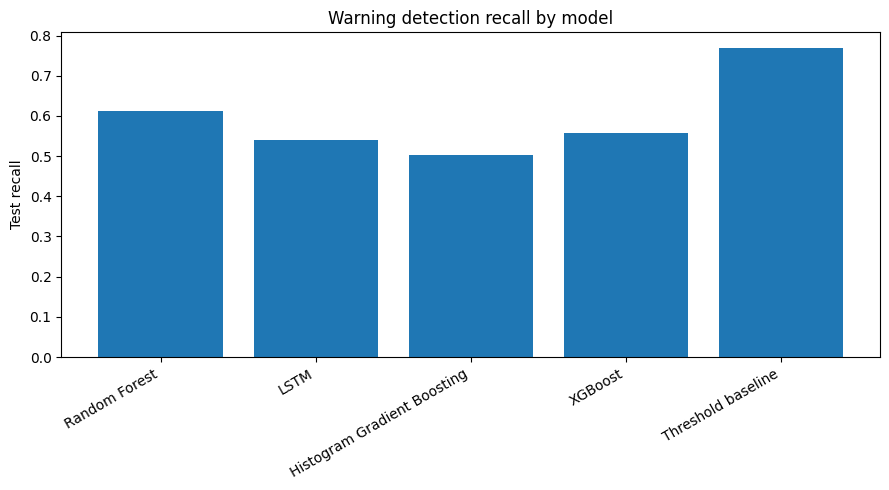

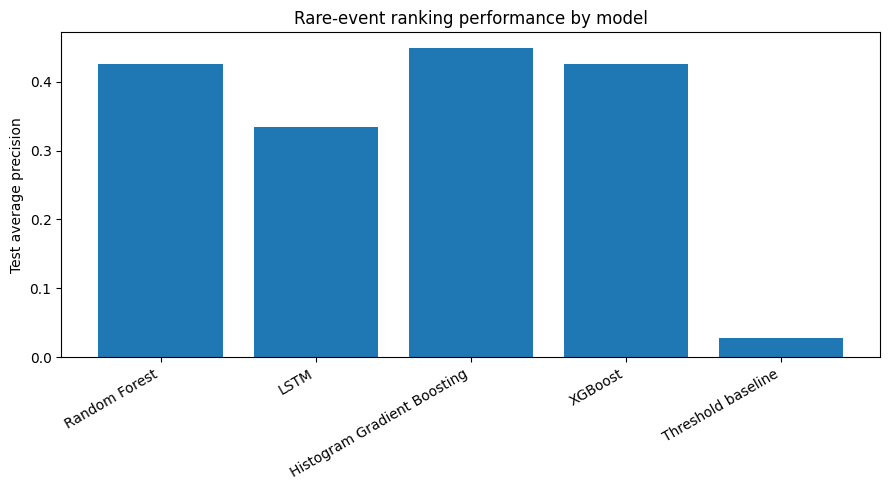

In [10]:

import os
import gc
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    precision_score, recall_score, fbeta_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")

DATA_PATH = "/content/methane_training_data.csv"
OUTPUT_PATH = "/content/methane_model_comparison.joblib"
SEQ_LEN = 6
RANDOM_STATE = 42

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "methane_training_data.csv not found in /content."
    )

print("Loading prepared dataset...")
data = pd.read_csv(DATA_PATH)
data = data.replace([np.inf, -np.inf], np.nan)
data["target"] = pd.to_numeric(data["target"], errors="coerce")
data = data.dropna(subset=["target"]).reset_index(drop=True)
data["target"] = data["target"].astype(int)

features = [
    c for c in data.columns
    if c != "target" and data[c].notna().any()
    and data[c].nunique(dropna=True) > 1
]

if "MM263" not in features:
    raise ValueError("MM263 is missing from the features.")

# Chronological split: final 20% stays untouched until evaluation.
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

train = data.iloc[:train_end].copy()
val = data.iloc[train_end:val_end].copy()
test = data.iloc[val_end:].copy()

y_train = train["target"].to_numpy()
y_val = val["target"].to_numpy()
y_test = test["target"].to_numpy()

print("Total rows:", n)
print("Features:", len(features))
print("Train positives:", int(y_train.sum()))
print("Validation positives:", int(y_val.sum()))
print("Test positives:", int(y_test.sum()))

if min(y_train.sum(), y_val.sum(), y_test.sum()) == 0:
    raise ValueError("One split has no positive events; comparison is unreliable.")

# Imputation is fitted on training data only.
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(train[features]).astype(np.float32)
X_val = imputer.transform(val[features]).astype(np.float32)
X_test = imputer.transform(test[features]).astype(np.float32)

# Cap training size for memory/runtime stability.
# Randomly sample from TRAINING ONLY; validation/test remain chronological.
rng = np.random.default_rng(RANDOM_STATE)
MAX_TRAIN_ROWS = min(250_000, len(y_train))

if len(y_train) > MAX_TRAIN_ROWS:
    sampled_idx = np.sort(
        rng.choice(len(y_train), size=MAX_TRAIN_ROWS, replace=False)
    )
else:
    sampled_idx = np.arange(len(y_train))

X_fit = X_train[sampled_idx]
y_fit = y_train[sampled_idx]

print("Rows used for fitting:", len(y_fit))

# Threshold is chosen using validation data only.
threshold_grid = np.unique(np.concatenate([
    np.arange(0.01, 0.201, 0.01),
    np.arange(0.22, 0.951, 0.02)
]))

def choose_threshold(y, scores):
    best = None
    for threshold in threshold_grid:
        pred = (scores >= threshold).astype(int)
        precision = precision_score(y, pred, zero_division=0)
        recall = recall_score(y, pred, zero_division=0)
        f2 = fbeta_score(y, pred, beta=2, zero_division=0)

        # Maximize validation F2; break ties using precision.
        key = (f2, precision)
        if best is None or key > best["key"]:
            best = {
                "key": key,
                "threshold": float(threshold),
                "precision": float(precision),
                "recall": float(recall),
                "f2": float(f2)
            }
    return best

results = []
fitted_models = {}

def evaluate_candidate(name, model, val_scores, test_scores,
                       val_y, test_y, threshold=None):
    if threshold is None:
        selection = choose_threshold(val_y, val_scores)
        threshold = selection["threshold"]
    else:
        selection = {
            "threshold": float(threshold),
            "precision": precision_score(
                val_y, val_scores >= threshold, zero_division=0
            ),
            "recall": recall_score(
                val_y, val_scores >= threshold, zero_division=0
            ),
            "f2": fbeta_score(
                val_y, val_scores >= threshold,
                beta=2, zero_division=0
            )
        }

    pred = (test_scores >= threshold).astype(int)
    cm = confusion_matrix(test_y, pred, labels=[0, 1])
    ap = average_precision_score(test_y, test_scores)
    auc = (
        roc_auc_score(test_y, test_scores)
        if len(np.unique(test_y)) == 2 else np.nan
    )

    result = {
        "model": name,
        "threshold": float(threshold),
        "val_precision": float(selection["precision"]),
        "val_recall": float(selection["recall"]),
        "val_F2": float(selection["f2"]),
        "test_precision": precision_score(
            test_y, pred, zero_division=0
        ),
        "test_recall": recall_score(
            test_y, pred, zero_division=0
        ),
        "test_F2": fbeta_score(
            test_y, pred, beta=2, zero_division=0
        ),
        "test_average_precision": ap,
        "test_ROC_AUC": auc,
        "TN": int(cm[0, 0]),
        "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]),
        "TP": int(cm[1, 1])
    }

    results.append(result)
    fitted_models[name] = {
        "model": model,
        "threshold": float(threshold)
    }

    print(
        f"{name}: threshold={threshold:.3f}, "
        f"test recall={result['test_recall']:.3f}, "
        f"precision={result['test_precision']:.3f}, "
        f"F2={result['test_F2']:.3f}, "
        f"AP={result['test_average_precision']:.3f}"
    )

    return result

# Use the same final test rows for all candidates.
# For the sequence model, trim the first SEQ_LEN-1 rows from every model.
y_val_common = y_val[SEQ_LEN - 1:]
y_test_common = y_test[SEQ_LEN - 1:]

X_val_common = X_val[SEQ_LEN - 1:]
X_test_common = X_test[SEQ_LEN - 1:]

print("\n1. Sensor-threshold baseline")
# Simple rule: flag if current MM263 is at least 0.6% CH4.
mm263_index = features.index("MM263")
baseline_val = (X_val_common[:, mm263_index] >= 0.6).astype(float)
baseline_test = (X_test_common[:, mm263_index] >= 0.6).astype(float)

evaluate_candidate(
    "Threshold baseline", None,
    baseline_val, baseline_test,
    y_val_common, y_test_common,
    threshold=0.5
)

print("\n2. Random Forest")
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight={0: 1, 1: 20},
    n_jobs=-1,
    random_state=RANDOM_STATE
)
rf.fit(X_fit, y_fit)
rf_val = rf.predict_proba(X_val)[:, 1][SEQ_LEN - 1:]
rf_test = rf.predict_proba(X_test)[:, 1][SEQ_LEN - 1:]
evaluate_candidate(
    "Random Forest", rf, rf_val, rf_test,
    y_val_common, y_test_common
)
del rf_val, rf_test
gc.collect()

print("\n3. Histogram Gradient Boosting")
hgb = HistGradientBoostingClassifier(
    max_iter=120,
    learning_rate=0.06,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=2.0,
    random_state=RANDOM_STATE
)
hgb_weights = np.where(y_fit == 1, 20.0, 1.0)
hgb.fit(X_fit, y_fit, sample_weight=hgb_weights)
hgb_val = hgb.predict_proba(X_val)[:, 1][SEQ_LEN - 1:]
hgb_test = hgb.predict_proba(X_test)[:, 1][SEQ_LEN - 1:]
evaluate_candidate(
    "Histogram Gradient Boosting", hgb, hgb_val, hgb_test,
    y_val_common, y_test_common
)
del hgb_val, hgb_test
gc.collect()

print("\n4. XGBoost")
try:
    from xgboost import XGBClassifier

    negatives = max(1, int((y_fit == 0).sum()))
    positives = max(1, int((y_fit == 1).sum()))

    xgb = XGBClassifier(
        n_estimators=350,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=2.0,
        scale_pos_weight=min(negatives / positives, 50),
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=2,
        random_state=RANDOM_STATE
    )
    xgb.fit(X_fit, y_fit)
    xgb_val = xgb.predict_proba(X_val)[:, 1][SEQ_LEN - 1:]
    xgb_test = xgb.predict_proba(X_test)[:, 1][SEQ_LEN - 1:]
    evaluate_candidate(
        "XGBoost", xgb, xgb_val, xgb_test,
        y_val_common, y_test_common
    )
    del xgb_val, xgb_test
    gc.collect()

except ImportError:
    print("XGBoost unavailable; skipped. Install with: !pip install xgboost")

print("\n5. LSTM sequence model")
try:
    import tensorflow as tf
    from sklearn.preprocessing import StandardScaler

    tf.keras.utils.set_random_seed(RANDOM_STATE)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
    X_val_scaled = scaler.transform(X_val).astype(np.float32)
    X_test_scaled = scaler.transform(X_test).astype(np.float32)

    # Each sequence contains six 10-second samples (60 seconds of history).
    def make_sequence_dataset(X, y, shuffle=False):
        return tf.keras.utils.timeseries_dataset_from_array(
            data=X,
            targets=y[SEQ_LEN - 1:],
            sequence_length=SEQ_LEN,
            sequence_stride=1,
            sampling_rate=1,
            batch_size=256,
            shuffle=shuffle,
            seed=RANDOM_STATE
        )

    train_ds = make_sequence_dataset(
        X_train_scaled, y_train, shuffle=True
    )
    val_ds = make_sequence_dataset(
        X_val_scaled, y_val, shuffle=False
    )
    test_ds = make_sequence_dataset(
        X_test_scaled, y_test, shuffle=False
    )

    lstm = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(SEQ_LEN, len(features))),
        tf.keras.layers.LSTM(32, dropout=0.15),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    lstm.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=3,
            restore_best_weights=True
        )
    ]

    # Class weighting is applied only during training.
    lstm.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        callbacks=callbacks,
        class_weight={0: 1.0, 1: 20.0},
        verbose=1
    )

    lstm_val = lstm.predict(val_ds, verbose=0).ravel()
    lstm_test = lstm.predict(test_ds, verbose=0).ravel()

    evaluate_candidate(
        "LSTM", lstm, lstm_val, lstm_test,
        y_val_common, y_test_common
    )

    fitted_models["LSTM"]["scaler"] = scaler

    del train_ds, val_ds, test_ds
    del X_train_scaled, X_val_scaled, X_test_scaled
    gc.collect()

except (ImportError, ModuleNotFoundError):
    print("TensorFlow unavailable; LSTM skipped.")
except Exception as e:
    print("LSTM failed:", repr(e))
    print("Other model comparisons will continue.")

print("\n" + "=" * 70)
print("MODEL COMPARISON ON THE SAME FINAL TEST PERIOD")
print("=" * 70)

comparison = pd.DataFrame(results).sort_values(
    ["val_F2", "val_precision"],
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

# Selection is based only on validation F2, never test metrics.
winner_name = comparison.iloc[0]["model"]
winner = fitted_models[winner_name]

print("\nSelected using validation F2:", winner_name)
print("Selected threshold:", round(winner["threshold"], 4))

if winner_name == "Threshold baseline":
    print(
        "The baseline won. This means the tested ML models have not "
        "demonstrated a better validation F2 than the simple sensor rule."
    )
else:
    print("The selected candidate is a trained model.")

# Show detailed final-test metrics for the selected candidate.
selected_row = comparison[comparison["model"] == winner_name].iloc[0]

print("\nSelected candidate's test metrics:")
for col in [
    "test_precision", "test_recall", "test_F2",
    "test_average_precision", "test_ROC_AUC",
    "TN", "FP", "FN", "TP"
]:
    print(f"{col}: {selected_row[col]}")

# Save all fitted candidates and their validation-selected thresholds.
joblib.dump({
    "selected_model_name": winner_name,
    "selected_threshold": winner["threshold"],
    "selected_model": winner["model"],
    "imputer": imputer,
    "features": features,
    "comparison_table": comparison,
    "all_models": fitted_models,
    "target_sensor": "MM263",
    "warning_level_percent_ch4": 1.0,
    "prediction_horizon_seconds": 60,
    "sampling_interval_seconds": 10,
    "sequence_length": SEQ_LEN,
    "note": (
        "Research prototype. Selection uses validation F2. "
        "Final test is chronological. Not certified for mine safety."
    )
}, OUTPUT_PATH)

print("\nSaved model comparison bundle:", OUTPUT_PATH)

plt.figure(figsize=(9, 5))
plt.bar(comparison["model"], comparison["test_recall"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("Test recall")
plt.title("Warning detection recall by model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(comparison["model"], comparison["test_average_precision"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("Test average precision")
plt.title("Rare-event ranking performance by model")
plt.tight_layout()
plt.show()


1. Loading prepared data...
Rows: 586784
Train: 410742 positives: 1941
Validation: 58673 positives: 100
Test: 117357 positives: 269
Features: 27

2. Sensor-threshold baseline...
Sensor threshold >=0.6%: threshold=0.500, validation F2=0.399, test recall=0.770, test precision=0.035

3. Random Forest...
Random Forest: threshold=0.260, validation F2=0.708, test recall=0.595, test precision=0.376

4. Histogram Gradient Boosting...
Histogram Gradient Boosting: threshold=0.120, validation F2=0.707, test recall=0.550, test precision=0.171

5. XGBoost...
XGBoost: threshold=0.020, validation F2=0.698, test recall=0.621, test precision=0.151

6. LSTM with aligned sequence targets...
Epoch 1/12
1605/1605 ━━━━━━━━━━━━━━━━━━━━ 92s 55ms/step - loss: 0.1323 - val_loss: 0.1640
Epoch 2/12
1605/1605 ━━━━━━━━━━━━━━━━━━━━ 86s 53ms/step - loss: 0.0808 - val_loss: 0.0678
Epoch 3/12
1605/1605 ━━━━━━━━━━━━━━━━━━━━ 145s 55ms/step - loss: 0.0708 - val_loss: 0.0759
Epoch 4/12
1605/1605 ━━━━━━━━━━━━━━━━━━━━ 86s 53

,model,threshold,val_precision,val_recall,val_F2,test_precision,test_recall,test_F2,test_average_precision,test_ROC_AUC,TN,FP,FN,TP
0,Random Forest,0.26,0.5000,0.79,0.7079,0.3756,0.5948,0.5326,0.3953,0.9160,116817,266,109,160
1,Histogram Gradient Boosting,0.12,0.4969,0.79,0.7066,0.1707,0.5502,0.3809,0.3952,0.8825,116364,719,121,148
2,XGBoost,0.02,0.4500,0.81,0.6983,0.1507,0.6208,0.3823,0.4572,0.8947,116142,941,102,167
3,LSTM,0.10,0.4339,0.82,0.6961,0.2072,0.5167,0.3978,0.2953,0.9480,116551,532,130,139
4,Sensor threshold >=0.6%,0.50,0.1222,0.92,0.3990,0.0347,0.7695,0.1469,0.0272,0.8601,111318,5765,62,207



Selected by validation F2: Random Forest
Selected threshold: 0.26

Selected model's final test results:
Precision: 0.3756
Recall: 0.5948
F2: 0.5326
Average precision: 0.3953
ROC-AUC: 0.916
TN, FP, FN, TP: 116817 266 109 160

Saved comparison bundle: /content/methane_model_comparison_v2.joblib


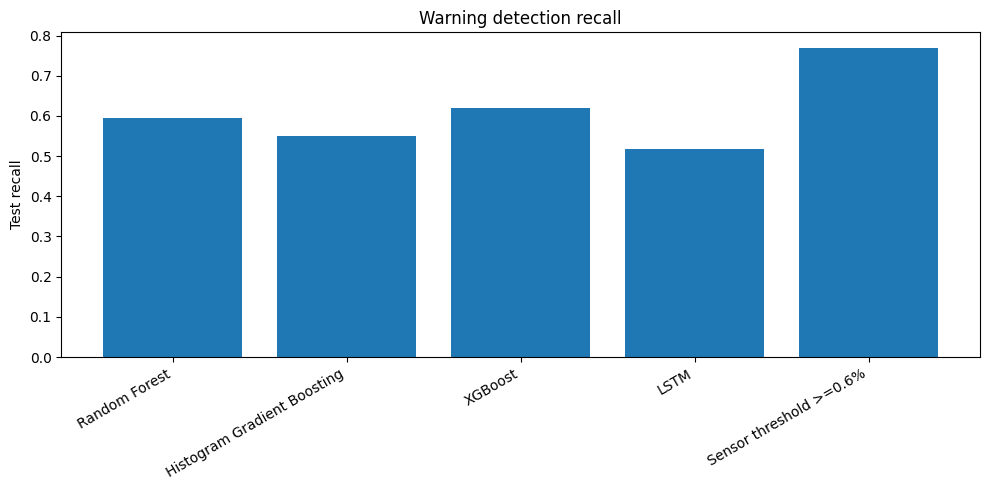

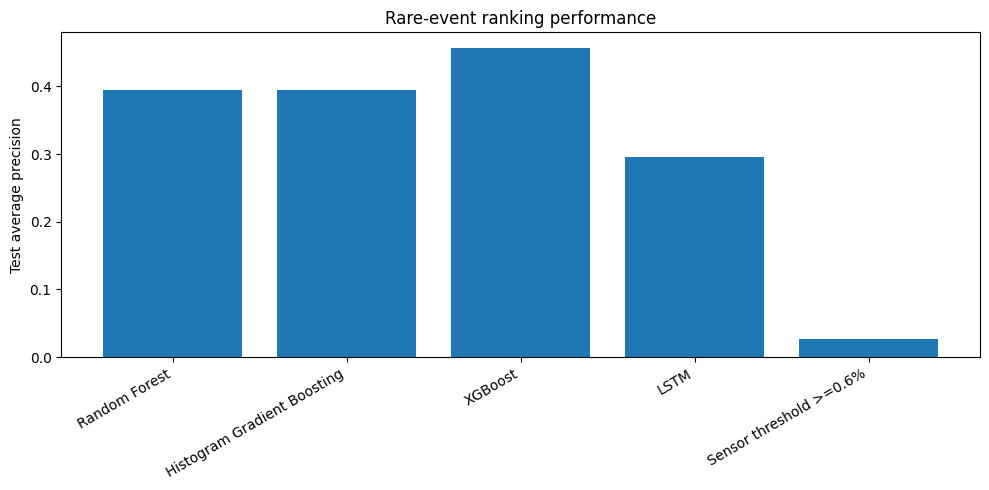

In [11]:

import os
import gc
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    precision_score, recall_score, fbeta_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")

DATA_PATH = "/content/methane_training_data.csv"
BUNDLE_PATH = "/content/methane_model_comparison_v2.joblib"
LSTM_PATH = "/content/methane_lstm_v2.keras"

SEED = 42
SEQ_LEN = 6
HORIZON_ROWS = 6
MAX_TRAIN_ROWS = 250_000

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Upload or restore /content/methane_training_data.csv first."
    )

np.random.seed(SEED)

print("1. Loading prepared data...")
data = pd.read_csv(DATA_PATH)
data = data.replace([np.inf, -np.inf], np.nan)
data["target"] = pd.to_numeric(data["target"], errors="coerce")
data = data.dropna(subset=["target"]).reset_index(drop=True)
data["target"] = data["target"].astype(int)

features = [
    c for c in data.columns
    if c != "target" and data[c].notna().any()
    and data[c].nunique(dropna=True) > 1
]

if "MM263" not in features:
    raise ValueError("MM263 is required for the sensor baseline.")

# Chronological split with a six-row embargo at each boundary.
# Each row represents 10 seconds and the target looks 60 seconds ahead.
n = len(data)
cut1 = int(n * 0.70)
cut2 = int(n * 0.80)

train = data.iloc[:cut1 - HORIZON_ROWS].copy()
val = data.iloc[cut1:cut2 - HORIZON_ROWS].copy()
test = data.iloc[cut2:].copy()

y_train = train["target"].to_numpy(dtype=np.int8)
y_val = val["target"].to_numpy(dtype=np.int8)
y_test = test["target"].to_numpy(dtype=np.int8)

print("Rows:", n)
print("Train:", len(train), "positives:", int(y_train.sum()))
print("Validation:", len(val), "positives:", int(y_val.sum()))
print("Test:", len(test), "positives:", int(y_test.sum()))
print("Features:", len(features))

if min(y_train.sum(), y_val.sum(), y_test.sum()) == 0:
    raise ValueError("A chronological split has no positive cases.")

# Fit preprocessing only on the training period.
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(train[features]).astype(np.float32)
X_val = imputer.transform(val[features]).astype(np.float32)
X_test = imputer.transform(test[features]).astype(np.float32)

# Cap the tree-model training size for Colab stability.
rng = np.random.default_rng(SEED)
if len(y_train) > MAX_TRAIN_ROWS:
    fit_idx = np.sort(
        rng.choice(len(y_train), MAX_TRAIN_ROWS, replace=False)
    )
else:
    fit_idx = np.arange(len(y_train))

X_fit = X_train[fit_idx]
y_fit = y_train[fit_idx]

# All models are evaluated on common rows after sequence warm-up.
eval_start = SEQ_LEN - 1
yv = y_val[eval_start:]
yt = y_test[eval_start:]
Xvc = X_val[eval_start:]
Xtc = X_test[eval_start:]

threshold_grid = np.unique(np.r_[
    np.arange(0.01, 0.201, 0.01),
    np.arange(0.22, 0.951, 0.02)
])

results = []
models = {}

def choose_threshold(y, scores):
    best = None
    for t in threshold_grid:
        pred = (scores >= t).astype(int)
        p = precision_score(y, pred, zero_division=0)
        r = recall_score(y, pred, zero_division=0)
        f2 = fbeta_score(y, pred, beta=2, zero_division=0)
        candidate = (f2, p, r, float(t))
        if best is None or candidate[:2] > best[:2]:
            best = candidate
    return {
        "f2": best[0],
        "precision": best[1],
        "recall": best[2],
        "threshold": best[3]
    }

def record_model(name, model, val_scores, test_scores,
                 fixed_threshold=None, extra=None):
    if fixed_threshold is None:
        chosen = choose_threshold(yv, val_scores)
        threshold = chosen["threshold"]
    else:
        threshold = fixed_threshold
        vp = (val_scores >= threshold).astype(int)
        chosen = {
            "threshold": threshold,
            "precision": precision_score(yv, vp, zero_division=0),
            "recall": recall_score(yv, vp, zero_division=0),
            "f2": fbeta_score(yv, vp, beta=2, zero_division=0)
        }

    pred = (test_scores >= threshold).astype(int)
    cm = confusion_matrix(yt, pred, labels=[0, 1])

    row = {
        "model": name,
        "threshold": threshold,
        "val_precision": chosen["precision"],
        "val_recall": chosen["recall"],
        "val_F2": chosen["f2"],
        "test_precision": precision_score(yt, pred, zero_division=0),
        "test_recall": recall_score(yt, pred, zero_division=0),
        "test_F2": fbeta_score(yt, pred, beta=2, zero_division=0),
        "test_average_precision": average_precision_score(yt, test_scores),
        "test_ROC_AUC": (
            roc_auc_score(yt, test_scores)
            if len(np.unique(yt)) == 2 else np.nan
        ),
        "TN": int(cm[0, 0]),
        "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]),
        "TP": int(cm[1, 1])
    }

    results.append(row)
    models[name] = {
        "model": model,
        "threshold": float(threshold),
        "extra": extra
    }

    print(
        f"{name}: threshold={threshold:.3f}, "
        f"validation F2={chosen['f2']:.3f}, "
        f"test recall={row['test_recall']:.3f}, "
        f"test precision={row['test_precision']:.3f}"
    )

print("\n2. Sensor-threshold baseline...")
# Fixed rule: alert when current MM263 >= 0.6%.
mm_idx = features.index("MM263")
baseline_val = (Xvc[:, mm_idx] >= 0.6).astype(float)
baseline_test = (Xtc[:, mm_idx] >= 0.6).astype(float)

record_model(
    "Sensor threshold >=0.6%",
    None, baseline_val, baseline_test,
    fixed_threshold=0.5
)

print("\n3. Random Forest...")
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=10,
    max_features="sqrt",
    n_jobs=-1,
    random_state=SEED
)
rf_weights = np.where(y_fit == 1, 20.0, 1.0)
rf.fit(X_fit, y_fit, sample_weight=rf_weights)

rf_val = rf.predict_proba(X_val)[:, 1][eval_start:]
rf_test = rf.predict_proba(X_test)[:, 1][eval_start:]
record_model("Random Forest", rf, rf_val, rf_test)
del rf_val, rf_test
gc.collect()

print("\n4. Histogram Gradient Boosting...")
hgb = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=3.0,
    random_state=SEED
)
hgb.fit(X_fit, y_fit, sample_weight=rf_weights)

hgb_val = hgb.predict_proba(X_val)[:, 1][eval_start:]
hgb_test = hgb.predict_proba(X_test)[:, 1][eval_start:]
record_model("Histogram Gradient Boosting", hgb, hgb_val, hgb_test)
del hgb_val, hgb_test
gc.collect()

print("\n5. XGBoost...")
try:
    from xgboost import XGBClassifier

    n_pos = max(1, int(y_fit.sum()))
    n_neg = max(1, len(y_fit) - n_pos)

    xgb = XGBClassifier(
        n_estimators=350,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=3.0,
        scale_pos_weight=min(n_neg / n_pos, 50),
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=2,
        random_state=SEED
    )
    xgb.fit(X_fit, y_fit)

    xgb_val = xgb.predict_proba(X_val)[:, 1][eval_start:]
    xgb_test = xgb.predict_proba(X_test)[:, 1][eval_start:]
    record_model("XGBoost", xgb, xgb_val, xgb_test)
    del xgb_val, xgb_test
    gc.collect()

except ImportError:
    print("XGBoost not installed; skipped.")

print("\n6. LSTM with aligned sequence targets...")
try:
    import tensorflow as tf
    from sklearn.preprocessing import StandardScaler

    tf.keras.utils.set_random_seed(SEED)

    scaler = StandardScaler()
    Xtr_s = scaler.fit_transform(X_train).astype(np.float32)
    Xv_s = scaler.transform(X_val).astype(np.float32)
    Xt_s = scaler.transform(X_test).astype(np.float32)

    def make_ds(X, y, training=False):
        # Target at index i is paired with the sequence ending at i.
        ds = tf.keras.utils.timeseries_dataset_from_array(
            data=X,
            targets=y[SEQ_LEN - 1:],
            sequence_length=SEQ_LEN,
            sequence_stride=1,
            sampling_rate=1,
            batch_size=256,
            shuffle=training,
            seed=SEED
        )
        return ds

    train_ds = make_ds(Xtr_s, y_train, training=True)
    val_ds = make_ds(Xv_s, y_val)
    test_ds = make_ds(Xt_s, y_test)

    # Weighted loss encourages the network to pay attention to rare events.
    positive_weight = tf.constant(20.0, dtype=tf.float32)

    def weighted_binary_crossentropy(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, (-1,)), tf.float32)
        y_pred = tf.clip_by_value(
            tf.reshape(y_pred, (-1,)), 1e-7, 1.0 - 1e-7
        )
        loss = -(
            positive_weight * y_true * tf.math.log(y_pred)
            + (1.0 - y_true) * tf.math.log(1.0 - y_pred)
        )
        return tf.reduce_mean(loss)

    lstm = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(SEQ_LEN, len(features))),
        tf.keras.layers.LSTM(32, dropout=0.15),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    lstm.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=weighted_binary_crossentropy
    )

    lstm.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    lstm_val = lstm.predict(val_ds, verbose=0).ravel()
    lstm_test = lstm.predict(test_ds, verbose=0).ravel()

    record_model(
        "LSTM", lstm, lstm_val, lstm_test,
        extra={"scaler": scaler}
    )
    lstm.save(LSTM_PATH)

    del train_ds, val_ds, test_ds, Xtr_s, Xv_s, Xt_s
    gc.collect()

except Exception as e:
    print("LSTM unavailable or failed:", repr(e))

print("\n7. Comparing models...")
comparison = pd.DataFrame(results).sort_values(
    ["val_F2", "val_precision"],
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

# Select by validation F2 only, not by test metrics.
winner_name = comparison.iloc[0]["model"]
winner = models[winner_name]

print("\nSelected by validation F2:", winner_name)
print("Selected threshold:", winner["threshold"])

selected_row = comparison.iloc[0]
print("\nSelected model's final test results:")
print("Precision:", round(selected_row["test_precision"], 4))
print("Recall:", round(selected_row["test_recall"], 4))
print("F2:", round(selected_row["test_F2"], 4))
print("Average precision:", round(selected_row["test_average_precision"], 4))
print("ROC-AUC:", round(selected_row["test_ROC_AUC"], 4))
print("TN, FP, FN, TP:",
      selected_row["TN"], selected_row["FP"],
      selected_row["FN"], selected_row["TP"])

if winner_name != "Sensor threshold >=0.6%":
    model_to_save = winner["model"]
else:
    model_to_save = None

joblib.dump({
    "selected_model_name": winner_name,
    "selected_threshold": winner["threshold"],
    "selected_model": model_to_save,
    "imputer": imputer,
    "features": features,
    "comparison": comparison,
    "all_models": models,
    "lstm_path": LSTM_PATH if "LSTM" in models else None,
    "target_sensor": "MM263",
    "warning_level_percent_ch4": 1.0,
    "prediction_horizon_seconds": 60,
    "sampling_interval_seconds": 10,
    "note": (
        "Research prototype only. Threshold chosen on validation F2. "
        "Final chronological test is not used for selection."
    )
}, BUNDLE_PATH)

print("\nSaved comparison bundle:", BUNDLE_PATH)

plt.figure(figsize=(10, 5))
plt.bar(comparison["model"], comparison["test_recall"])
plt.ylabel("Test recall")
plt.title("Warning detection recall")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(comparison["model"], comparison["test_average_precision"])
plt.ylabel("Test average precision")
plt.title("Rare-event ranking performance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [17]:
import os
import gc
import joblib
import numpy as np
import pandas as pd

from collections import Counter
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, fbeta_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, classification_report
)

RAW_FILE = "/content/methane_data.csv"
DATA_FILE = "/content/methane_training_data_fixed.csv"
MODEL_FILE = "/content/methane_random_forest_fixed.joblib"

THRESHOLD = 1.0
INVALID_MAX = 5.0
HORIZON = 60
SAMPLE_EVERY = 10
MIN_VALID_FUTURE = 54
CHUNK_SIZE = 100_000

columns = [
    "year", "month", "day", "hour", "minute", "second",
    "AN311", "AN422", "AN423", "TP1721", "RH1722", "BA1723",
    "TP1711", "RH1712", "BA1713", "MM252", "MM261", "MM262",
    "MM263", "MM264", "MM256", "MM211", "CM861", "CR863",
    "P_864", "TC862", "WM868", "AMP1_IR", "AMP2_IR", "DMP3_IR",
    "DMP4_IR", "AMP5_IR", "F_SIDE", "V"
]

sensor_cols = columns[6:]
feature_cols = sensor_cols + ["hour_sin", "hour_cos"]

if not os.path.exists(RAW_FILE):
    raise FileNotFoundError(f"Original dataset not found: {RAW_FILE}")

if os.path.exists(DATA_FILE):
    os.remove(DATA_FILE)

pending = pd.DataFrame(columns=columns)
total_rows = 0
written_rows = 0
label_counts = Counter()
first_write = True

reader = pd.read_csv(
    RAW_FILE,
    header=None,
    skiprows=1,
    names=columns,
    chunksize=CHUNK_SIZE,
    on_bad_lines="skip"
)

for chunk in reader:
    for col in columns:
        chunk[col] = pd.to_numeric(chunk[col], errors="coerce")

    combined = pd.concat([pending, chunk], ignore_index=True)
    global_start = total_rows - len(pending)
    total_rows += len(chunk)

    if len(combined) <= HORIZON:
        pending = combined.tail(HORIZON).copy()
        continue

    usable_n = len(combined) - HORIZON
    methane = combined["MM263"].to_numpy(dtype=np.float32)

    valid = (
        np.isfinite(methane)
        & (methane >= 0)
        & (methane <= INVALID_MAX)
    )
    valid_event = valid & (methane >= THRESHOLD)

    valid_windows = sliding_window_view(
        valid[1:], HORIZON
    )[:usable_n]

    event_windows = sliding_window_view(
        valid_event[1:], HORIZON
    )[:usable_n]

    valid_counts = valid_windows.sum(axis=1)
    future_event = event_windows.any(axis=1)

    keep_label = future_event | (
        valid_counts >= MIN_VALID_FUTURE
    )
    target = future_event.astype(np.uint8)

    positions = global_start + np.arange(usable_n)
    sampled = (
        (positions % SAMPLE_EVERY == 0)
        & keep_label
    )

    if sampled.any():
        out = combined.iloc[
            np.flatnonzero(sampled)
        ].copy()

        out["target"] = target[sampled]

        mm263 = out["MM263"].to_numpy(dtype=np.float64)

        bad_current = (
            ~np.isfinite(mm263)
            | (mm263 < 0)
            | (mm263 > INVALID_MAX)
        )

        out.loc[bad_current, "MM263"] = np.nan

        hour_values = pd.to_numeric(
            out["hour"], errors="coerce"
        ).to_numpy(dtype=np.float64)

        out["hour_sin"] = np.sin(
            2 * np.pi * hour_values / 24
        )
        out["hour_cos"] = np.cos(
            2 * np.pi * hour_values / 24
        )

        out = out[feature_cols + ["target"]]

        out.to_csv(
            DATA_FILE,
            index=False,
            mode="w" if first_write else "a",
            header=first_write
        )

        first_write = False
        written_rows += len(out)
        label_counts.update(
            out["target"].astype(int).tolist()
        )

    pending = combined.tail(HORIZON).copy()

    del combined, chunk
    gc.collect()

print("Label generation completed.")
print("Raw rows processed:", total_rows)
print("Training rows saved:", written_rows)
print("Positive labels:", label_counts[1])
print("Negative labels:", label_counts[0])
print("Training file:", DATA_FILE)

if written_rows == 0 or label_counts[1] == 0:
    raise ValueError(
        "No usable training rows or positive events were found."
    )

df = pd.read_csv(DATA_FILE)
df = df.replace([np.inf, -np.inf], np.nan)

n = len(df)
split1 = int(n * 0.70)
split2 = int(n * 0.85)
embargo = HORIZON // SAMPLE_EVERY

train = df.iloc[:max(0, split1 - embargo)].copy()

val = df.iloc[
    min(n, split1 + embargo):
    max(split1 + embargo, split2 - embargo)
].copy()

test = df.iloc[min(n, split2 + embargo):].copy()

X_train = train[feature_cols]
y_train = train["target"].astype(int)

X_val = val[feature_cols]
y_val = val["target"].astype(int)

X_test = test[feature_cols]
y_test = test["target"].astype(int)

print("\nSplit sizes:", len(train), len(val), len(test))
print(
    "Positive counts:",
    int(y_train.sum()),
    int(y_val.sum()),
    int(y_test.sum())
)

if (
    y_train.nunique() < 2
    or y_val.sum() == 0
    or y_test.sum() == 0
):
    raise ValueError(
        "A split has no positive examples. "
        "Check label counts before training."
    )

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight={0: 1, 1: 20},
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

val_probs = model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.02, 0.801, 0.01)
best_threshold = 0.5
best_f2 = -1

for threshold in thresholds:
    preds = (val_probs >= threshold).astype(int)

    score = fbeta_score(
        y_val,
        preds,
        beta=2,
        zero_division=0
    )

    if score > best_f2:
        best_f2 = score
        best_threshold = float(threshold)

test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (
    test_probs >= best_threshold
).astype(int)

print("\nSelected validation threshold:", round(best_threshold, 3))
print("Validation F2:", round(best_f2, 4))

print("\nTEST RESULTS")
print(
    "Precision:",
    round(precision_score(y_test, test_preds, zero_division=0), 4)
)
print(
    "Recall:",
    round(recall_score(y_test, test_preds, zero_division=0), 4)
)
print(
    "F2-score:",
    round(fbeta_score(y_test, test_preds, beta=2, zero_division=0), 4)
)
print(
    "PR-AUC / Average Precision:",
    round(average_precision_score(y_test, test_probs), 4)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, test_probs), 4)
)

print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_preds))

print("\nClassification report:")
print(classification_report(y_test, test_preds, zero_division=0))

joblib.dump({
    "model": model,
    "threshold": best_threshold,
    "feature_cols": feature_cols,
    "target_threshold": THRESHOLD,
    "prediction_horizon_seconds": HORIZON,
    "minimum_valid_future_readings": MIN_VALID_FUTURE
}, MODEL_FILE)

print("\nSaved model:", MODEL_FILE)

Label generation completed.
Raw rows processed: 6206369
Training rows saved: 590897
Positive labels: 2343
Negative labels: 588554
Training file: /content/methane_training_data_fixed.csv

Split sizes: 413621 88623 88629
Positive counts: 1960 133 250

Selected validation threshold: 0.24
Validation F2: 0.6713

TEST RESULTS
Precision: 0.4401
Recall: 0.588
F2-score: 0.551
PR-AUC / Average Precision: 0.4288
ROC-AUC: 0.9011

Confusion matrix [[TN, FP], [FN, TP]]:
[[88192   187]
 [  103   147]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     88379
           1       0.44      0.59      0.50       250

    accuracy                           1.00     88629
   macro avg       0.72      0.79      0.75     88629
weighted avg       1.00      1.00      1.00     88629


Saved model: /content/methane_random_forest_fixed.joblib
